# Lead Service Line Analysis

## AI-Assisted Data Story for a Public Issue

**Organization:** Xylem / IBM SkillsBuild  
**Data Source:** U.S. Environmental Protection Agency (EPA), SDWIS Service Line Inventory  
**Reporting Period:** 2026 Q2

### Research Question

**Where are lead service line infrastructure needs greatest across U.S. states?**

This analysis examines two related dimensions of that infrastructure challenge:

- **Identification need:** service lines whose material remains classified as Lead Status Unknown
- **Replacement need:** service lines already classified as Lead or Galvanized Requiring Replacement (GRR)

The analysis first compares the absolute scale of these needs across states and then examines whether the interpretation changes after accounting for population served.

A Lead Status Unknown service line is **not assumed to be a lead service line**. It represents a service line whose material has not yet been demonstrated to be Lead, GRR, or Non-lead.

## 1. Data Source

The primary dataset is the EPA SDWIS Service Line Inventory for 2026 Q2.

**Raw file:** `SDWIS_service_line_inventory_2026Q2.csv`

The original CSV is preserved unchanged. All filtering, cleaning, calculations, validation checks, and aggregation are performed reproducibly within this notebook.

Relevant fields include:

- Lead service lines
- Galvanized Requiring Replacement (GRR) service lines
- Lead Status Unknown service lines
- Non-lead service lines
- Total reported service lines
- Public Water System (PWS) type
- Service-line reporting status
- Primacy agency
- EPA region
- Population served

The analysis focuses on reported infrastructure inventories. It does not measure household lead exposure, drinking-water lead concentrations, or health risk.

## 2. Analytical Framework

Lead service line infrastructure need is treated as a multidimensional issue rather than a single ranking.

For this analysis:

**Known Replacement Inventory = Lead Service Lines + Galvanized Requiring Replacement Service Lines**

This represents service lines already classified into categories requiring lead-related replacement action.

**Identification Need = Lead Status Unknown Service Lines**

This represents service lines whose material classification remains unresolved.

These measures represent different stages of the same infrastructure process:

**Unknown → Identify material → Classify as Lead / GRR / Non-lead → Replace where required**

The analysis does not combine replacement and identification needs into a single composite score.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

## 3. Load Raw Data

The EPA CSV is loaded directly from the preserved raw file.

The file requires `cp1252` character encoding. `low_memory=False` is used so pandas reads the dataset without chunk-based type inference.

No cleaning or transformations are performed during this step.

In [2]:
raw_df = pd.read_csv(
    "SDWIS_service_line_inventory_2026Q2.csv",
    encoding="cp1252",
    low_memory=False
)

print(f"Rows: {raw_df.shape[0]:,}")
print(f"Columns: {raw_df.shape[1]}")

Rows: 66,429
Columns: 22


In [3]:
raw_df["Submission Year Quarter"].value_counts(dropna=False)

Submission Year Quarter
2026Q2    66429
Name: count, dtype: int64

## 4. Initial Data Inspection

Before filtering or cleaning, the raw dataset is inspected for its structure, data types, missing values, and reporting completeness.

In [4]:
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 66429 entries, 0 to 66428
Data columns (total 22 columns):
 #   Column                                            Non-Null Count  Dtype 
---  ------                                            --------------  ----- 
 0   Submission Year Quarter                           66429 non-null  object
 1   PWS ID                                            66429 non-null  object
 2   PWS Name                                          66429 non-null  object
 3   # Galvanized Requiring Replacement Service Lines  59062 non-null  object
 4   # Lead Service Lines                              58918 non-null  object
 5   # Lead Status Unknown Service Lines               59652 non-null  object
 6   # Non-lead Service Lines                          59620 non-null  object
 7   Total # Service Lines Reported                    60109 non-null  object
 8   Any Service Line Type Reported                    66429 non-null  object
 9   Service Line Report Status  

In [5]:
relevant_columns = [
    "# Lead Service Lines",
    "# Galvanized Requiring Replacement Service Lines",
    "# Lead Status Unknown Service Lines",
    "# Non-lead Service Lines",
    "Total # Service Lines Reported",
    "Population Served Count"
]

raw_df[relevant_columns].isna().sum()

# Lead Service Lines                                7511
# Galvanized Requiring Replacement Service Lines    7367
# Lead Status Unknown Service Lines                 6777
# Non-lead Service Lines                            6809
Total # Service Lines Reported                      6320
Population Served Count                                0
dtype: int64

In [6]:
raw_df["PWS Type"].value_counts()

PWS Type
Community water system                49378
Non-Transient non-community system    17051
Name: count, dtype: int64

In [7]:
raw_df["Service Line Report Status"].value_counts()

Service Line Report Status
Reported all required service line types          58825
Did not report any required service line types     6674
Reported some but not all service line types        930
Name: count, dtype: int64

### Initial Inspection Notes

The raw file contains multiple water-system types and reporting-completeness levels. Several service-line count fields also contain missing values and are stored as text because some values include commas.

The analysis will therefore restrict the sample to Community Water Systems with complete required service-line reporting, preserve missing values during numeric conversion, and explicitly limit the geographic comparison to the 50 states and District of Columbia.

## 5. Define Analytical Scope

The main analysis focuses on Community Water Systems with complete required service-line reporting in the 50 U.S. states and District of Columbia.

These filters are applied sequentially so the effect of each scope decision can be verified.

In [8]:
df = raw_df.copy()

In [9]:
df = df[df["PWS Type"] == "Community water system"].copy()

print(f"Community Water Systems: {len(df):,}")

Community Water Systems: 49,378


In [10]:
df = df[
    df["Service Line Report Status"] == "Reported all required service line types"
].copy()

print(f"Complete Community Water System reports: {len(df):,}")

Complete Community Water System reports: 44,957


In [11]:
states_dc = [
    "Alabama", "Alaska", "Arizona", "Arkansas", "California", "Colorado",
    "Connecticut", "Delaware", "District of Columbia", "Florida", "Georgia",
    "Hawaii", "Idaho", "Illinois", "Indiana", "Iowa", "Kansas", "Kentucky",
    "Louisiana", "Maine", "Maryland", "Massachusetts", "Michigan", "Minnesota",
    "Mississippi", "Missouri", "Montana", "Nebraska", "Nevada", "New Hampshire",
    "New Jersey", "New Mexico", "New York", "North Carolina", "North Dakota",
    "Ohio", "Oklahoma", "Oregon", "Pennsylvania", "Rhode Island",
    "South Carolina", "South Dakota", "Tennessee", "Texas", "Utah", "Vermont",
    "Virginia", "Washington", "West Virginia", "Wisconsin", "Wyoming"
]

df = df[df["Primacy Agency"].isin(states_dc)].copy()

print(f"Final analytical sample: {len(df):,}")

Final analytical sample: 43,993


In [12]:
print(f"Rows: {len(df):,}")
print(f"Unique PWS IDs: {df['PWS ID'].nunique():,}")
print(f"Duplicate PWS IDs: {df['PWS ID'].duplicated().sum():,}")

Rows: 43,993
Unique PWS IDs: 43,993
Duplicate PWS IDs: 0


### Scope Result

The analysis is limited to **Community Water Systems** in the **50 states and District of Columbia** that **reported all required service-line types**.

This produces a final analytical sample of **43,993 systems** and avoids treating incomplete reporting as true zero values.

Each PWS ID appears once in the final sample, so no deduplication is required.

## 6. Data Cleaning

Relevant service-line and population fields are stored as text because some values contain commas. These fields are converted to numeric values while preserving missing values.

In [13]:
numeric_columns = [
    "# Galvanized Requiring Replacement Service Lines",
    "# Lead Service Lines",
    "# Lead Status Unknown Service Lines",
    "# Non-lead Service Lines",
    "Total # Service Lines Reported",
    "Population Served Count"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col].astype("string").str.replace(",", "", regex=False),
        errors="coerce"
    )

In [14]:
pd.DataFrame({
    "Data Type": df[numeric_columns].dtypes.astype(str),
    "Missing Values": df[numeric_columns].isna().sum()
})

,Data Type,Missing Values
# Galvanized Requiring Replacement Service Lines,Int64,0
# Lead Service Lines,Int64,0
# Lead Status Unknown Service Lines,Int64,0
# Non-lead Service Lines,Int64,16
Total # Service Lines Reported,Int64,0
Population Served Count,Int64,0


## 7. Derived Metrics

Two measures are used to represent different stages of lead service line infrastructure need:

- **Known Replacement Inventory** = Lead Service Lines + Galvanized Requiring Replacement Service Lines
- **Identification Need** = Lead Status Unknown Service Lines

In [15]:
df["Known Replacement Inventory"] = (
    df["# Lead Service Lines"]
    + df["# Galvanized Requiring Replacement Service Lines"]
)

df["Identification Need"] = df["# Lead Status Unknown Service Lines"]

In [16]:
category_sum = (
    df["# Lead Service Lines"]
    + df["# Galvanized Requiring Replacement Service Lines"]
    + df["# Lead Status Unknown Service Lines"]
    + df["# Non-lead Service Lines"].fillna(0)
)

total_matches = category_sum == df["Total # Service Lines Reported"]

print(f"Rows matching reported total: {total_matches.sum():,} of {len(df):,}")
print(f"Rows not matching: {(~total_matches).sum():,}")

Rows matching reported total: 43,993 of 43,993
Rows not matching: 0


### Validation

For all **43,993 systems**, the reported service-line categories reconcile with the reported total service-line count.

For the 16 records with missing Non-lead values, Lead + GRR + Unknown already equals the reported total, so the missing Non-lead field does not affect the core metrics used in this analysis.

## 8. State-Level Aggregation

System-level records are aggregated by state to compare the scale of replacement and identification needs across the 50 states and District of Columbia.

In [17]:
state_summary = (
    df.groupby("Primacy Agency")
      .agg(
          Systems=("PWS ID", "count"),
          Population_Served=("Population Served Count", "sum"),
          Lead=("# Lead Service Lines", "sum"),
          GRR=("# Galvanized Requiring Replacement Service Lines", "sum"),
          Known_Replacement=("Known Replacement Inventory", "sum"),
          Unknown=("Identification Need", "sum")
      )
      .reset_index()
      .rename(columns={"Primacy Agency": "State"})
)

In [18]:
print(f"States + DC: {len(state_summary)}")
print(f"Total systems represented: {state_summary['Systems'].sum():,}")

States + DC: 51
Total systems represented: 43,993


## 9. National Inventory Context

National totals are calculated from the final analytical sample to establish the overall scale of known replacement inventory and unresolved identification need before comparing states.

In [19]:
national_totals = pd.DataFrame({
    "Category": ["Lead", "GRR", "Unknown"],
    "Service Lines": [
        df["# Lead Service Lines"].sum(),
        df["# Galvanized Requiring Replacement Service Lines"].sum(),
        df["# Lead Status Unknown Service Lines"].sum()
    ]
})

national_totals

,Category,Service Lines
0,Lead,2179217
1,GRR,936091
2,Unknown,21589524


In [20]:
national_known_replacement = (
    national_totals.loc[
        national_totals["Category"].isin(["Lead", "GRR"]),
        "Service Lines"
    ].sum()
)

print(f"Known Replacement Inventory: {national_known_replacement:,.0f}")
print(f"Identification Need: {national_totals.loc[national_totals['Category'] == 'Unknown', 'Service Lines'].iloc[0]:,.0f}")

Known Replacement Inventory: 3,115,308
Identification Need: 21,589,524


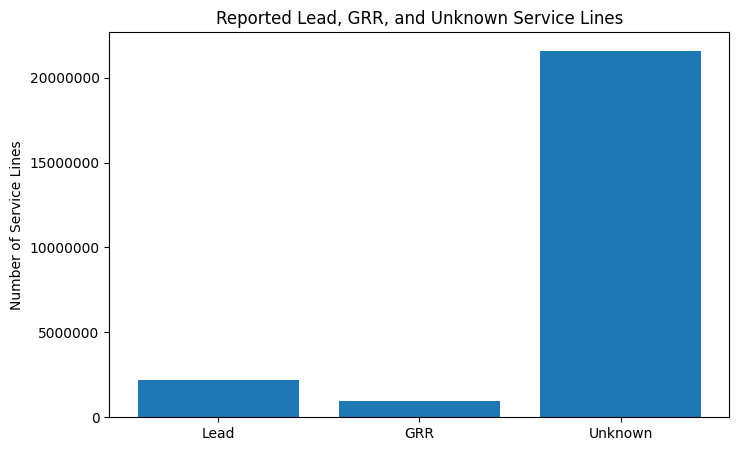

In [21]:
plt.figure(figsize=(8, 5))

plt.bar(
    national_totals["Category"],
    national_totals["Service Lines"]
)

plt.title("Reported Lead, GRR, and Unknown Service Lines")
plt.ylabel("Number of Service Lines")
plt.ticklabel_format(style="plain", axis="y")

plt.show()

### Initial Finding

Within the analytical sample, approximately **3.1 million service lines are already classified as Lead or GRR**, while approximately **21.6 million remain classified as Lead Status Unknown**. The much larger unknown inventory indicates that unresolved identification is a major part of the reported infrastructure picture, but unknown lines should not be interpreted as confirmed lead lines.

## 10. State-Level Infrastructure Needs

State totals are compared to identify where known replacement inventories and unresolved identification needs are most concentrated.

In [22]:
state_summary.sort_values(
    "Known_Replacement",
    ascending=False
)[
    ["State", "Known_Replacement", "Unknown", "Systems"]
].head(10)

,State,Known_Replacement,Unknown,Systems
13,Illinois,672210,529706,1635
35,Ohio,321502,878788,1101
32,New York,289055,951163,2211
22,Michigan,255524,301508,1349
14,Indiana,190947,545507,744
49,Wisconsin,158815,182814,1021
30,New Jersey,135360,860857,555
43,Texas,114501,2178881,4341
38,Pennsylvania,113717,2055512,1770
23,Minnesota,87183,209216,959
